In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score

In [ ]:
train = pd.read_csv("/content/house-data/house_train.csv")
test = pd.read_csv("/content/house-data/house_test.csv")

print("Training Data Shape:", train.shape)
print("Testing Data Shape:", test.shape)

print("\nTraining Data:")
print(train.head())

print("\nTesting Data:")
print(test.head())

Training Data Shape: (2000, 10)
Testing Data Shape: (1000, 9)

Training Data:
   ID  Location Paint_Color  Lot_Width  Lot_Depth  Year_Sold  Year_Built  \
0   1    Suburb       Green        134        NaN       2020        1990   
1   2  Downtown       Green         76       93.0       2025        2019   
2   3    Suburb      Yellow         91       83.0       2019        2003   
3   4    Suburb       Green         26       21.0       2022        1995   
4   5     Rural         Red        138       85.0       2017        1980   

   Living_Area  Num_Rooms      Price  
0          813          6  1548800.0  
1         3093          6  1974800.0  
2         2845          3  2466950.0  
3         1837          3   968700.0  
4         4928          8  2570700.0  

Testing Data:
     ID  Location Paint_Color  Lot_Width  Lot_Depth  Year_Sold  Year_Built  \
0  2001     Rural       Green        106        131       2023        1980   
1  2002     Rural       Green         98         23       20

In [ ]:
print("Training Columns:")
print(train.columns.tolist())

print("\nMissing Values in Training Data:")
print(train.isnull().sum())

print("\nMissing Values in Testing Data:")
print(test.isnull().sum())

X_train = train.drop(columns=["Price", "ID"])
y_train = train["Price"]

X_test = test.drop(columns=["ID"])

print("\nFeatures used for prediction:")
print(X_train.columns.tolist())

Training Columns:
['ID', 'Location', 'Paint_Color', 'Lot_Width', 'Lot_Depth', 'Year_Sold', 'Year_Built', 'Living_Area', 'Num_Rooms', 'Price']

Missing Values in Training Data:
ID               0
Location         0
Paint_Color      0
Lot_Width        0
Lot_Depth      279
Year_Sold        0
Year_Built       0
Living_Area      0
Num_Rooms        0
Price            0
dtype: int64

Missing Values in Testing Data:
ID             0
Location       0
Paint_Color    0
Lot_Width      0
Lot_Depth      0
Year_Sold      0
Year_Built     0
Living_Area    0
Num_Rooms      0
dtype: int64

Features used for prediction:
['Location', 'Paint_Color', 'Lot_Width', 'Lot_Depth', 'Year_Sold', 'Year_Built', 'Living_Area', 'Num_Rooms']


In [ ]:
numerical_features = [
    "Lot_Width",
    "Lot_Depth",
    "Year_Sold",
    "Year_Built",
    "Living_Area",
    "Num_Rooms"
]

categorical_features = [
    "Location",
    "Paint_Color"
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Lot_Width', 'Lot_Depth', 'Year_Sold', 'Year_Built', 'Living_Area', 'Num_Rooms']

Categorical Features:
['Location', 'Paint_Color']


In [ ]:
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Data preprocessing setup completed.")

Data preprocessing setup completed.


In [ ]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_train)

linear_r2 = r2_score(y_train, linear_predictions)

print("Linear Regression Model")
print("-----------------------")
print("R² Score:", linear_r2)

Linear Regression Model
-----------------------
R² Score: 0.2874975834354767


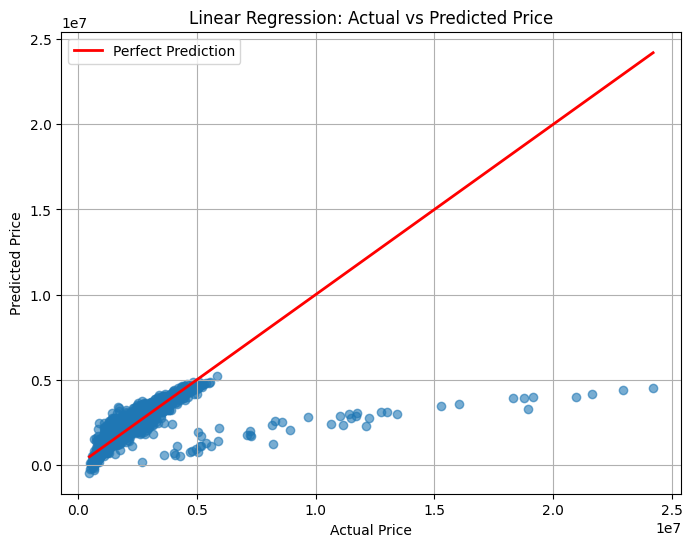

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_train,
    linear_predictions,
    alpha=0.6
)

plt.plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    color="red",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression: Actual vs Predicted Price")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
polynomial_numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

polynomial_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

polynomial_preprocessor = ColumnTransformer([
    (
        "num",
        polynomial_numerical_transformer,
        numerical_features
    ),
    (
        "cat",
        polynomial_categorical_transformer,
        categorical_features
    )
])

polynomial_model = Pipeline([
    ("preprocessor", polynomial_preprocessor),
    ("regressor", Ridge(alpha=10))
])

polynomial_model.fit(X_train, y_train)

polynomial_predictions = polynomial_model.predict(X_train)

polynomial_r2 = r2_score(
    y_train,
    polynomial_predictions
)

print("Polynomial Regression Model")
print("--------------------------")
print("R² Score:", polynomial_r2)

Polynomial Regression Model
--------------------------
R² Score: 0.33110509309103664


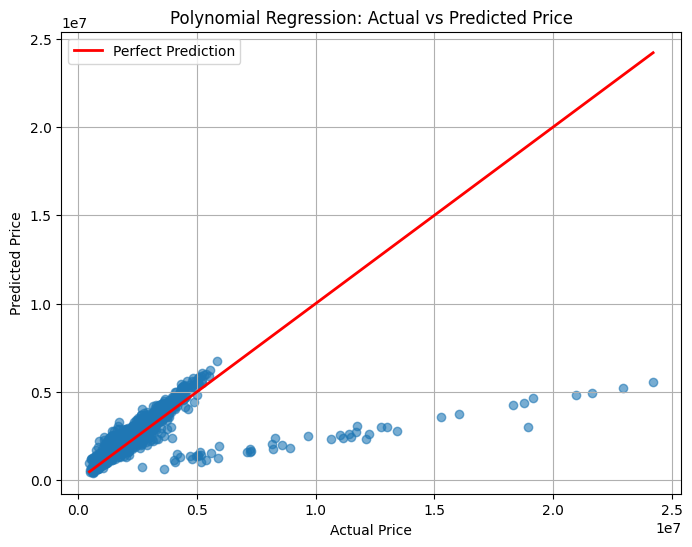

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_train,
    polynomial_predictions,
    alpha=0.6
)

plt.plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    color="red",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Polynomial Regression: Actual vs Predicted Price")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print("\n================================")
print("REGRESSION MODEL COMPARISON")
print("================================")

print(f"Linear Regression R²:     {linear_r2:.4f}")
print(f"Polynomial Regression R²: {polynomial_r2:.4f}")

if polynomial_r2 > linear_r2:
    print("\nPolynomial Regression performs better.")
    best_model = polynomial_model
    best_model_name = "Polynomial Regression"
else:
    print("\nLinear Regression performs better.")
    best_model = linear_model
    best_model_name = "Linear Regression"

print("\nBest Model:", best_model_name)


REGRESSION MODEL COMPARISON
Linear Regression R²:     0.2875
Polynomial Regression R²: 0.3311

Polynomial Regression performs better.

Best Model: Polynomial Regression


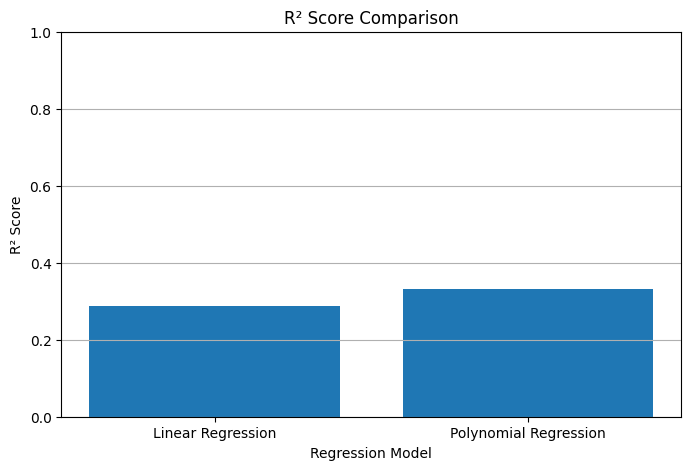

In [ ]:
models = [
    "Linear Regression",
    "Polynomial Regression"
]

r2_scores = [
    linear_r2,
    polynomial_r2
]

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    r2_scores
)

plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.title("R² Score Comparison")

plt.ylim(0, 1)
plt.grid(axis="y")

plt.show()

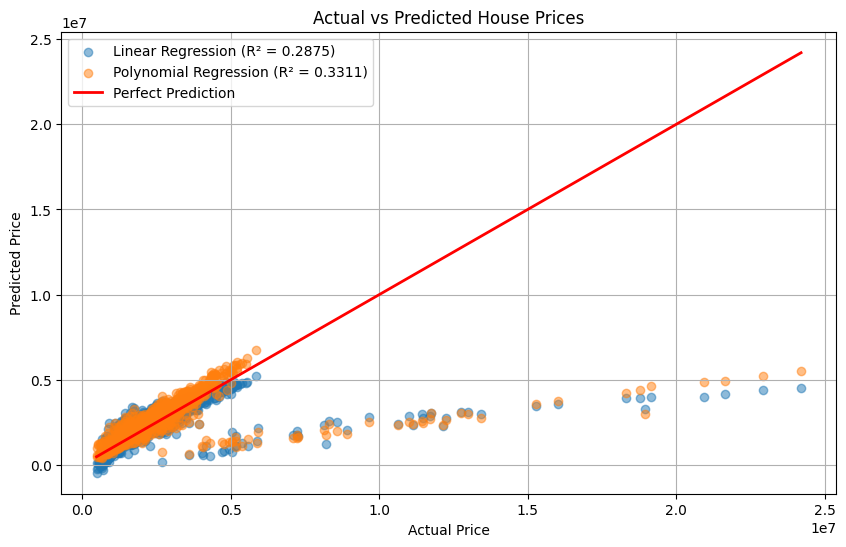

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_train,
    linear_predictions,
    alpha=0.5,
    label=f"Linear Regression (R² = {linear_r2:.4f})"
)

plt.scatter(
    y_train,
    polynomial_predictions,
    alpha=0.5,
    label=f"Polynomial Regression (R² = {polynomial_r2:.4f})"
)

plt.plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    color="red",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_predictions = best_model.predict(X_test)

test_results = test.copy()

test_results["Predicted_Price"] = test_predictions

print("\nTesting Data Predictions:")
print(test_results[[
    "ID",
    "Predicted_Price"
]].head(10))


Testing Data Predictions:
     ID  Predicted_Price
0  2001     2.400271e+06
1  2002     2.970216e+06
2  2003     8.353549e+05
3  2004     2.352630e+06
4  2005     2.096054e+06
5  2006     1.821913e+06
6  2007     6.342580e+06
7  2008     2.865372e+06
8  2009     1.286060e+06
9  2010     4.031739e+06


In [ ]:
test_results.to_csv(
    "house_price_predictions.csv",
    index=False
)

print("\nPredictions saved successfully as:")
print("house_price_predictions.csv")


Predictions saved successfully as:
house_price_predictions.csv


In [ ]:
print("\n========================================")
print("FINAL RESULT")
print("========================================")

print(f"Linear Regression R²:     {linear_r2:.4f}")
print(f"Polynomial Regression R²: {polynomial_r2:.4f}")

print(f"\nBest Model: {best_model_name}")

print("\nData cleaning performed:")
print("1. Removed ID column")
print("2. Filled missing numerical values using median")
print("3. Filled missing categorical values using most frequent value")
print("4. Encoded categorical variables")
print("5. Polynomial features of degree 2 used")
print("6. Ridge regularization used to reduce noise/overfitting")


FINAL RESULT
Linear Regression R²:     0.2875
Polynomial Regression R²: 0.3311

Best Model: Polynomial Regression

Data cleaning performed:
1. Removed ID column
2. Filled missing numerical values using median
3. Filled missing categorical values using most frequent value
4. Encoded categorical variables
5. Polynomial features of degree 2 used
6. Ridge regularization used to reduce noise/overfitting
